# Лабораторная работа 1. Прогноз RiskScore

Обучаю линейную регрессию прогнозировать числовой балл риска по признакам кредитной заявки. Для публикации ноутбука в задании указан порог MSE ниже 25,00. Цель доработки посылки v5 — публичный MSE ниже 19. Результаты Kaggle для первых двух посылок составили 19,2661695 и 19,4569822. Дальше показаны учебные реализации, сравнение моделей и экспорт v5.

Запускайте ячейки по порядку в ядре Python с NumPy, pandas, Matplotlib, SciPy, scikit-learn и ipykernel. Файлы train.csv, test.csv и ex.csv лежат в папке data рядом с ноутбуком.

[Условие работы](docs/cml_lab1.pdf) · [Соревнование на Kaggle](https://www.kaggle.com/t/d71c922786884244aa7092cf51b22406)

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from sklearn import metrics
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, SGDRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
TARGET = "RiskScore"
LAB = Path("lab1") if Path("lab1/lab1.ipynb").is_file() else Path(".")
# Для небольших матриц один поток BLAS уменьшает накладные расходы.
blas_limit = threadpool_limits(limits=1, user_api="blas")
pd.options.display.float_format = "{:,.5f}".format

## 1. Метрики и масштабирование

MSE усредняет квадраты ошибок и сильнее реагирует на крупные промахи. MAE показывает среднюю абсолютную ошибку в единицах RiskScore. $R^2$ сравнивает ошибку с прогнозом средним значением. MAPE делит абсолютную ошибку на модуль истинного ответа. Функция возвращает долю, как в sklearn, а в таблицах результат переведён в проценты.

При z-score вычитаю среднее и делю на стандартное отклонение обучающей части. При min-max вычитаю минимум и делю на размах. Для постоянного признака использую делитель 1.

In [2]:
def mse(y, pred):
    return np.mean(np.square(np.asarray(y, dtype=float) - pred))


def mae(y, pred):
    return np.mean(np.abs(np.asarray(y, dtype=float) - pred))


def r2(y, pred):
    y = np.asarray(y, dtype=float)
    if len(y) < 2:
        return np.nan
    total = np.sum((y - y.mean()) ** 2)
    residual = np.sum((y - pred) ** 2)
    if total == 0:
        return float(residual == 0)
    return 1 - residual / total


def mape(y, pred):
    y = np.asarray(y, dtype=float)
    denominator = np.maximum(np.abs(y), np.finfo(float).eps)
    return np.mean(np.abs(y - pred) / denominator)


def scores(y, pred):
    return {"MSE": mse(y, pred), "MAE": mae(y, pred),
            "R²": r2(y, pred), "MAPE, %": 100 * mape(y, pred)}


class Scaler:
    def __init__(self, method="z-score"):
        self.method = method

    def fit(self, X):
        if self.method == "z-score":
            self.offset_, scale = X.mean(axis=0), X.std(axis=0)
        elif self.method == "min-max":
            self.offset_, scale = X.min(axis=0), np.ptp(X, axis=0)
        else:
            raise ValueError("Выберите z-score или min-max")
        self.scale_ = np.where(scale == 0, 1, scale)
        return self

    def transform(self, X):
        return (X - self.offset_) / self.scale_

In [3]:
truth = np.array([1., 2., 4.])
guess = np.array([2., 2., 2.])
own = [mse(truth, guess), mae(truth, guess), r2(truth, guess), mape(truth, guess)]
reference = [metrics.mean_squared_error(truth, guess), metrics.mean_absolute_error(truth, guess),
             metrics.r2_score(truth, guess), metrics.mean_absolute_percentage_error(truth, guess)]
np.testing.assert_allclose(own, [5/3, 1, -1/14, 0.5])
np.testing.assert_allclose(own, reference)
assert r2([3, 3], np.array([3, 3])) == 1
assert r2([3, 3], np.array([2, 2])) == 0
np.testing.assert_allclose(mape([0, 2], np.array([1., 2.])),
                           metrics.mean_absolute_percentage_error([0, 2], [1, 2]))
display(pd.DataFrame({"Своя формула": own, "sklearn": reference},
                     index=["MSE", "MAE", "R²", "MAPE (доля)"]))

example = np.array([[1., 7.], [3., 7.], [5., 7.]])
new_rows = np.array([[0., 7.], [7., 9.]])
for method, baseline in [("z-score", StandardScaler()), ("min-max", MinMaxScaler())]:
    np.testing.assert_allclose(Scaler(method).fit(example).transform(new_rows),
                               baseline.fit(example).transform(new_rows))
print("Оба способа масштабирования совпали со sklearn на новых строках.")

,Своя формула,sklearn
MSE,1.66667,1.66667
MAE,1.00000,1.00000
R²,-0.07143,-0.07143
MAPE (доля),0.50000,0.50000


Оба способа масштабирования совпали со sklearn на новых строках.


## 2. Три способа обучить линейную регрессию

Модель вычисляет $\hat y = b + Xw$. Центрирование признаков и цели позволяет найти свободный член отдельно как $b = \bar y - \bar X w$. Аналитический метод использует псевдообратную матрицу через SVD в `lstsq`. Так обрабатываются и линейно зависимые столбцы. Для полного градиентного спуска минимизирую половину MSE с шагом, обратным максимальному собственному значению $X^TX/n$. Стохастический метод обновляет веса по одной случайно выбранной в перестановке строке. Убывающий шаг и усреднение поздних весов уменьшают шум SGD.

In [4]:
class MyLinearRegression:
    def __init__(self, method="analytic", epochs=55, seed=SEED):
        self.method = method
        self.epochs = epochs
        self.seed = seed

    def fit(self, X, y, *, track_loss=False):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        center = X.mean(axis=0)
        A, target = X - center, y - y.mean()
        n, d = A.shape
        self.loss_history_ = []
        if self.method == "analytic":
            w = np.linalg.lstsq(A, target, rcond=None)[0]
        elif self.method == "gd":
            gram, rhs = (A.T @ A) / n, (A.T @ target) / n
            lipschitz = max(np.linalg.eigvalsh(gram)[-1], 1e-15)
            w = np.zeros(d)
            target_square = np.mean(target**2)
            for _ in range(self.epochs):
                gradient = gram @ w - rhs
                if np.max(np.abs(gradient)) < 1e-9:
                    break
                w -= gradient / lipschitz
                if track_loss:
                    # Раскрытый квадрат ошибки через уже вычисленные AᵀA/n и Aᵀy/n.
                    self.loss_history_.append(target_square + w @ (gram @ w - 2 * rhs))
        elif self.method == "sgd":
            rng = np.random.default_rng(self.seed)
            w, total = np.zeros(d), np.zeros(d)
            # Ограничиваем шаг с учётом самой длинной строки.
            initial_step = 0.8 / max(1., np.max(np.einsum("ij,ij->i", A, A)))
            count = 0
            for epoch in range(self.epochs):
                step = initial_step / (1 + epoch / 4)
                for i in rng.permutation(n):
                    w -= step * (A[i] @ w - target[i]) * A[i]
                if track_loss:
                    self.loss_history_.append(mse(target, A @ w))
                if epoch >= self.epochs // 2:
                    total += w
                    count += 1
            w = total / count
        else:
            raise ValueError("Неизвестный метод обучения")
        self.coef_ = w
        self.intercept_ = y.mean() - center @ w
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

## 3. Регуляризация

Для стандартизированных признаков минимизирую $\|y-b-Xw\|^2/(2n) + \lambda_1\sum |w_j| + (\lambda_p/p)\sum |w_j|^p$. Выбор $p=2$ даёт квадратичный штраф, сочетание с $\lambda_1$ — Elastic Net. При $p=1$ штраф сводится к L1. Свободный член не штрафуется. Параметр `p` задаёт пользователь, здесь рассматривается выпуклая задача $p\ge 1$.

Для L1 и Elastic Net записываю каждый вес как разность двух неотрицательных частей. Тогда L1-штраф равен сумме этих частей в минимуме. Для задачи с границами задаю собственную функцию потерь и градиент и использую L-BFGS-B. Для чистого L2 решаю систему линейных уравнений, для общего гладкого Lp передаю в SciPy собственные формулы функции потерь и градиента. Ниже сравниваю решения со sklearn, а для дробного $p$ проверяю градиент конечными разностями.

In [5]:
class RegularizedRegression:
    def __init__(self, l1=0., lp=0., p=2.):
        if min(l1, lp) < 0 or p < 1:
            raise ValueError("Требуется l1, lp ≥ 0 и p ≥ 1")
        self.l1, self.lp, self.p = l1, lp, p

    def smooth_loss(self, w, A, y):
        error = A @ w - y
        loss = (error @ error) / (2 * len(y)) + self.lp * np.sum(abs(w)**self.p) / self.p
        grad = A.T @ error / len(y) + self.lp * np.sign(w) * abs(w)**(self.p - 1)
        return loss, grad

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        center = X.mean(axis=0)
        A, target = X - center, y - y.mean()
        n, d = A.shape
        l1 = self.l1 + (self.lp if self.p == 1 else 0.)
        l2 = self.lp if self.p == 2 else 0.
        if self.p not in (1, 2) and self.lp > 0:
            if l1 > 0:
                raise ValueError("Для сочетания L1 и Lp используйте p=2 (Elastic Net)")
            result = minimize(self.smooth_loss, np.zeros(d), args=(A, target), jac=True,
                              method="L-BFGS-B", options={"maxiter": 3000, "ftol": 1e-14, "gtol": 1e-8})
            if not result.success:
                raise RuntimeError(result.message)
            w = result.x
        elif l1 > 0:
            gram, rhs = A.T @ A / n, A.T @ target / n
            # w = positive - negative, обе части неотрицательны.
            # При l1 > 0 в минимуме они не могут одновременно быть положительными.
            def split_loss(parts):
                w = parts[:d] - parts[d:]
                grad = gram @ w - rhs + l2 * w
                value = .5 * w @ (gram @ w) - rhs @ w + .5 * l2 * (w @ w) + l1 * parts.sum()
                return value, np.r_[grad + l1, -grad + l1]

            result = minimize(split_loss, np.zeros(2*d), jac=True, method="L-BFGS-B",
                              bounds=[(0., None)] * (2*d),
                              options={"maxiter": 5000, "maxfun": 15000, "ftol": 1e-14, "gtol": 1e-8})
            if not result.success:
                raise RuntimeError(result.message)
            w = result.x[:d] - result.x[d:]
        elif l2 > 0:
            w = np.linalg.solve(A.T @ A + n * l2 * np.eye(d), A.T @ target)
        else:
            w = np.linalg.lstsq(A, target, rcond=None)[0]
        self.coef_, self.intercept_ = w, y.mean() - center @ w
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

In [6]:
# Независимые проверки на маленькой матрице с известными коэффициентами.
rng = np.random.default_rng(SEED)
mini = rng.normal(size=(90, 4))
exact_y = 3 + mini @ np.array([1., -2., 0., 0.5])
for method, epochs in [("analytic", 1), ("gd", 400), ("sgd", 100)]:
    fitted = MyLinearRegression(method, epochs).fit(mini, exact_y)
    np.testing.assert_allclose(fitted.predict(mini), exact_y, atol=1e-6)

noisy_y = exact_y + rng.normal(0, 0.3, len(mini))
for model, ref in [(RegularizedRegression(l1=.1), Lasso(alpha=.1, tol=1e-10)),
                   (RegularizedRegression(lp=.1), Ridge(alpha=len(mini) * .1)),
                   (RegularizedRegression(l1=.06, lp=.04), ElasticNet(alpha=.1, l1_ratio=.6, tol=1e-10)),
                   (RegularizedRegression(lp=.1, p=1), Lasso(alpha=.1, tol=1e-10))]:
    np.testing.assert_allclose(model.fit(mini, noisy_y).predict(mini),
                               ref.fit(mini, noisy_y).predict(mini), atol=1e-6)
lp_test = RegularizedRegression(lp=.1, p=1.5)
point = np.array([-2., .4, 1.3, -.3])
steps = np.eye(len(point)) * 1e-6
numeric_grad = [(lp_test.smooth_loss(point+h, mini, noisy_y)[0]
                 - lp_test.smooth_loss(point-h, mini, noisy_y)[0]) / 2e-6 for h in steps]
np.testing.assert_allclose(lp_test.smooth_loss(point, mini, noisy_y)[1], numeric_grad, atol=1e-7)
lp_test.fit(mini, noisy_y)
_, grad = lp_test.smooth_loss(lp_test.coef_, mini-mini.mean(0), noisy_y-noisy_y.mean())
assert np.max(abs(grad)) < 1e-5
print("Три способа обучения, L1, L2, Elastic Net и Lp прошли численные проверки.")

Три способа обучения, L1, L2, Elastic Net и Lp прошли численные проверки.


## 4. Подготовка признаков и кросс-валидация

Для текстовых категорий строю индикаторы (one-hot). Дату заявки, если она есть, перевожу в дни от фиксированной даты. Отсутствующие числа получают 0 и отдельный индикатор пропуска. Такой способ сохраняет различие между пропуском и настоящим нулём. Набор столбцов кодировщика, средние и масштабы определяются по обучающей части каждого разбиения. Для новых категорий все уже известные индикаторы равны нулю.

In [7]:
def encode(frame):
    parts = []
    for name in frame:
        col = frame[name]
        if name.casefold().endswith("date"):
            dates = pd.to_datetime(col, errors="coerce", utc=True)
            col = (dates - pd.Timestamp("2000-01-01", tz="UTC")).dt.total_seconds() / 86400
        if pd.api.types.is_numeric_dtype(col):
            values = col.astype(float).replace([np.inf, -np.inf], np.nan)
            parts.append(pd.DataFrame({name: values.fillna(0),
                                       name + "__missing": values.isna().astype(float)}))
        else:
            category = col.astype("string").fillna("<пропуск>")
            parts.append(pd.get_dummies(category, prefix=name, dtype=float))
    return pd.concat(parts, axis=1)


class Features:
    def __init__(self, scaling="z-score", basis="base"):
        self.scaler = Scaler(scaling)
        self.basis = basis

    def encode(self, frame):
        if self.basis == "base":
            return encode(frame)
        if self.basis in ("conservative", "conservative_v4", "conservative_v5"):
            strength = 1. if self.basis == "conservative" else .4
            def profile(data):
                return conservative_profile(data, record_strength=strength, version5=self.basis == "conservative_v5")
            return profile_features(recover_financial_values(frame), credit_missing=frame.CreditScore.isna(),
                                    encoder=profile)
        if self.basis in ("profile", "profile_interactions", "grouped"):
            recovered = recover_financial_values(frame)
            return profile_features(recovered, interactions=self.basis != "profile", grouped=self.basis == "grouped",
                                    credit_missing=frame.CreditScore.isna())
        missing = frame.isna().any(axis=1).astype(float).rename("исходные пропуски")
        recovered = recover_financial_values(frame)
        return pd.concat([encode(recovered), financial_basis(recovered, self.basis), missing], axis=1)

    def fit(self, frame):
        encoded = self.encode(frame)
        self.columns = encoded.columns[encoded.nunique() > 1]
        if not len(self.columns):
            raise ValueError("Не найдено ни одного изменяющегося признака")
        self.scaler.fit(encoded[self.columns].to_numpy(dtype=float))
        return self

    def transform(self, frame):
        encoded = self.encode(frame).reindex(columns=self.columns, fill_value=0)
        result = self.scaler.transform(encoded.to_numpy(dtype=float))
        if self.basis in ("conservative", "conservative_v4", "conservative_v5"):
            # После стандартизации это эквивалентно штрафам 0,002 и 1 для двух блоков.
            result[:, self.columns.str.startswith("поправка · ")] *= np.sqrt(.002)
        if self.basis == "conservative_v5":
            result[:, self.columns == "поправка · возраст"] *= np.sqrt(3.5)
            result[:, self.columns == "возраст 30–50"] *= np.sqrt(.002 / .4)
        return result


def prepare(train_x, valid_x, method="z-score", basis="base"):
    features = Features(method, basis=basis).fit(train_x)
    return features.transform(train_x), features.transform(valid_x)


def kfold_indices(n, k=5, seed=SEED):
    if not 2 <= k <= n:
        raise ValueError("Требуется 2 ≤ k ≤ n")
    folds = np.array_split(np.random.default_rng(seed).permutation(n), k)
    for i, valid in enumerate(folds):
        yield np.concatenate(folds[:i] + folds[i+1:]), valid


def leave_one_out_indices(n):
    indices = np.arange(n)
    for i in range(n):
        yield np.concatenate([indices[:i], indices[i+1:]]), indices[i:i+1]


def cross_predict(frame, y, splits, factory):
    prediction = np.empty(len(y))
    fold_scores = []
    for train, valid in splits:
        A, B = prepare(frame.iloc[train], frame.iloc[valid])
        prediction[valid] = factory().fit(A, y[train]).predict(B)
        fold_scores.append(mse(y[valid], prediction[valid]))
    return prediction, fold_scores

При **k-fold** каждая строка получает прогноз модели, учившейся на остальных фолдах. Для **leave-one-out** тестовая часть состоит из одной строки. Выше записан прямой алгоритм. Для полного набора применяю точное ускорение для обычной линейной регрессии со свободным членом: ошибка на исключённой строке равна $e_i/(1-h_{ii})$, где $e_i$ — остаток модели на полном наборе, а $h_{ii}$ — диагональ матрицы проекции. Диагональ получаю из SVD без построения квадратной матрицы размера числа строк.

Центрирование и масштабирование не меняют пространство столбцов модели со свободным членом. При исчезновении уникальной категории или другом падении ранга ($h_{ii}\approx 1$) пересобираю предобработку и обучаю модель для этой строки буквально. Проверка ниже сопоставляет быстрый и прямой ответы.

In [8]:
def loo_ols(frame, y):
    features = Features().fit(frame)
    X = features.transform(frame)
    design = np.column_stack([np.ones(len(X)), X])
    U, singular, _ = np.linalg.svd(design, full_matrices=False)
    tol = np.finfo(float).eps * max(design.shape) * singular[0]
    basis = U[:, singular > tol]
    fitted = basis @ (basis.T @ y)
    leverage = np.einsum("ij,ij->i", basis, basis)
    regular = (1 - leverage) > 1e-8
    pred = np.empty_like(y, dtype=float)
    pred[regular] = y[regular] - (y[regular] - fitted[regular]) / (1 - leverage[regular])
    for i in np.flatnonzero(~regular):
        keep = np.arange(len(y)) != i
        A, B = prepare(frame.iloc[keep], frame.iloc[[i]])
        pred[i] = MyLinearRegression().fit(A, y[keep]).predict(B)[0]
    return pred


mini_frame = pd.DataFrame(mini[:32], columns=list("abcd"))
mini_frame["тип"] = ["А", "Б"] * 15 + ["А", "редкая"]
mini_frame.loc[[2, 5], "b"] = np.nan
parts = list(kfold_indices(32))
np.testing.assert_array_equal(np.sort(np.concatenate([v for _, v in parts])), np.arange(32))
assert all(not np.intersect1d(t, v).size for t, v in parts)
direct, _ = cross_predict(mini_frame, noisy_y[:32], leave_one_out_indices(32), MyLinearRegression)
np.testing.assert_allclose(loo_ols(mini_frame, noisy_y[:32]), direct, atol=1e-8)
print("Разбиения k-fold корректны. Быстрый LOO совпал с 32 отдельными переобучениями.")

Разбиения k-fold корректны. Быстрый LOO совпал с 32 отдельными переобучениями.


## 5. Данные и разведочный анализ

Загружаю официальные файлы соревнования. Идентификатор исключаю из признаков и сохраняю для отправки. Фиксирую отложенные 20% строк до анализа признаков. Графики и выбор настроек опираются на оставшиеся 80%.

В train встречаются пустые строки и две изолированные метки (−9 999 999 и 10 000 000). Удаляю только эти значения, строки без цели и точные дубликаты. Среди оставшихся данных дата заявки уникальна, поэтому повтор одной и той же записи не попадает в разные части. Частично заполненные заявки сохраняю.

In [9]:
folders = [LAB / "data", LAB]
data_dir = next((folder for folder in folders
                 if all((folder / f).is_file() for f in ("train.csv", "test.csv"))), None)
if data_dir is None:
    raise FileNotFoundError("Положите train.csv и test.csv соревнования в lab1/data или рядом с ноутбуком.")
train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
assert train.columns.is_unique and test.columns.is_unique
assert TARGET in train and TARGET not in test
raw_count = len(train)
blank_target = train[TARGET].isna()
invalid_target = train[TARGET].isin([-9_999_999, 10_000_000])
labelled = train.loc[~(blank_target | invalid_target)]
train = labelled.drop_duplicates().reset_index(drop=True)
print(f"Исходно {raw_count} строк. Без цели: {blank_target.sum()}; "
      f"две аномальные метки: {invalid_target.sum()}; "
      f"точных дубликатов среди оставшихся: {len(labelled)-len(train)}.")
assert train.ApplicationDate.is_unique
print(f"После очистки {len(train)} уникальных заявок. Частично заполненных: "
      f"{train.isna().any(axis=1).sum()}.")
id_names = {"id", "index", "rowid", "row_id", "loanid", "loan_id", "customerid", "customer_id",
            "applicationid", "application_id", "unnamed: 0"}
id_cols = [name for name in test if name.strip().casefold() in id_names]
features = [name for name in test if name not in id_cols]
if set(train) - set(id_cols) - {TARGET} != set(features):
    raise ValueError("Схемы train и test расходятся. Проверьте названия признаков и идентификаторов.")
X = train[features]
y = pd.to_numeric(train[TARGET], errors="raise").to_numpy(dtype=float)
assert np.isfinite(y).all()
dev, holdout = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED)
X_dev, X_hold = X.iloc[dev], X.iloc[holdout]
y_dev, y_hold = y[dev], y[holdout]
print(f"Строк в train: {len(train):,}, в test: {len(test):,}. Признаков: {len(features)}.")
print(f"Для разработки: {len(dev):,}, для финальной проверки: {len(holdout):,}. ID: {id_cols}.")
profile = pd.DataFrame({"Тип": X_dev.dtypes.astype(str), "Пропуски": X_dev.isna().sum(),
                        "Разных значений": X_dev.nunique()})
display(profile)
display(pd.Series(y_dev, name=TARGET).describe().to_frame().T)

Исходно 11017 строк. Без цели: 530; две аномальные метки: 215; точных дубликатов среди оставшихся: 484.
После очистки 9788 уникальных заявок. Частично заполненных: 456.
Строк в train: 9,788, в test: 5,000. Признаков: 34.
Для разработки: 7,830, для финальной проверки: 1,958. ID: ['ID'].


,Тип,Пропуски,Разных значений
ApplicationDate,str,0,7830
Age,float64,0,63
AnnualIncome,float64,0,4412
CreditScore,float64,366,547
LoanAmount,float64,366,6974
LoanDuration,float64,0,10
MaritalStatus,str,0,4
NumberOfDependents,float64,0,7
HomeOwnershipStatus,str,0,4
MonthlyDebtPayments,float64,366,1592


,count,mean,std,min,25%,50%,75%,max
RiskScore,"7,830.00000",48.26969,17.18208,18.85476,32.71535,44.22901,64.97022,97.59725


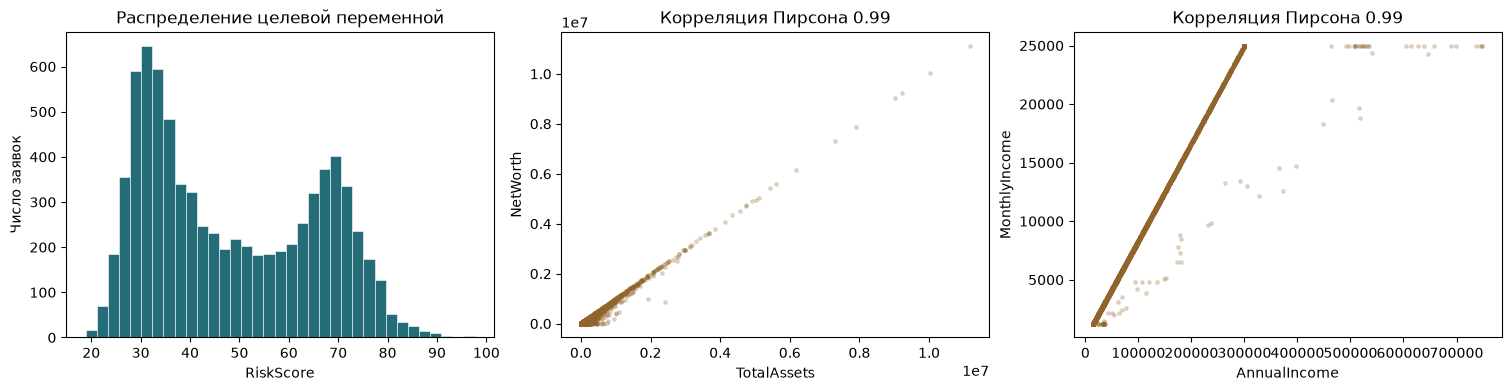

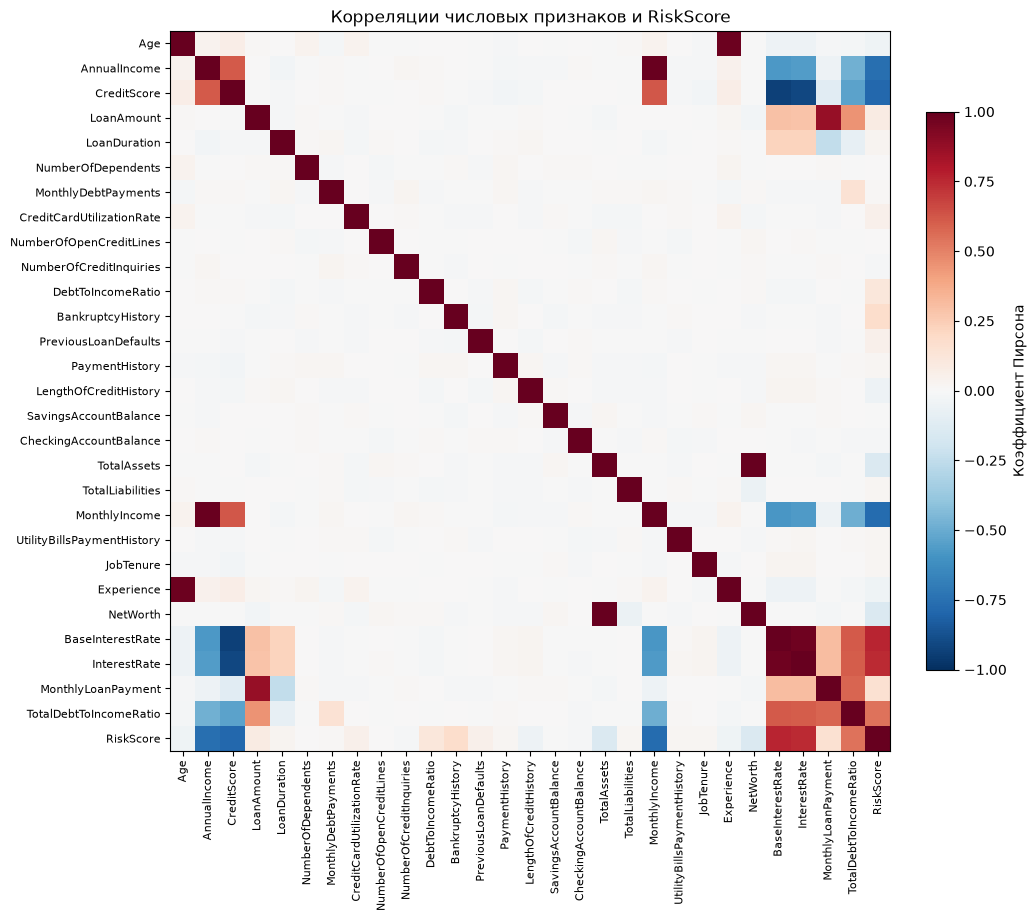

Медиана RiskScore — 44.23. Средние 50% значений лежат от 32.72 до 64.97.
Из числовых признаков самая сильная линейная связь с целью у CreditScore (r = -0.786).
Наиболее связанная пара признаков — TotalAssets и NetWorth (r = 0.993).
Они частично дублируют информацию. Веса таких столбцов могут быть неустойчивыми.


In [10]:
eda = X_dev.select_dtypes(include="number").copy()
eda[TARGET] = y_dev
corr = eda.corr()
target_corr = corr[TARGET].drop(TARGET).dropna().sort_values(key=abs, ascending=False)
feature_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool)).stack()
pairs = pairs.sort_values(key=abs, ascending=False)
fig, axes = plt.subplots(1, 1 + min(2, len(pairs)), figsize=(5 * (1 + min(2, len(pairs))), 3.8),
                         squeeze=False, layout="constrained")
axes = axes[0]
axes[0].hist(y_dev, bins=35, color="#246d78", edgecolor="white", linewidth=.4)
axes[0].set(xlabel=TARGET, ylabel="Число заявок", title="Распределение целевой переменной")
for ax, ((left, right), rho) in zip(axes[1:], pairs.head(2).items()):
    ax.scatter(eda[left], eda[right], s=6, alpha=.22, color="#90642a", rasterized=True)
    ax.set(xlabel=left, ylabel=right, title=f"Корреляция Пирсона {rho:.2f}")
plt.show()

size = max(6., .32 * len(corr))
fig, ax = plt.subplots(figsize=(size + 1, size), layout="constrained")
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.set_title("Корреляции числовых признаков и RiskScore")
fig.colorbar(heat, ax=ax, shrink=.72, label="Коэффициент Пирсона")
plt.show()

q1, median, q3 = np.quantile(y_dev, [.25, .5, .75])
print(f"Медиана RiskScore — {median:.2f}. Средние 50% значений лежат от {q1:.2f} до {q3:.2f}.")
if len(target_corr):
    top = target_corr.index[0]
    rho = target_corr.iloc[0]
    print(f"Из числовых признаков самая сильная линейная связь с целью у {top} (r = {rho:.3f}).")
if len(pairs):
    (first, second), rho = next(iter(pairs.items()))
    print(f"Наиболее связанная пара признаков — {first} и {second} (r = {rho:.3f}).")
    if abs(rho) > .85:
        print("Они частично дублируют информацию. Веса таких столбцов могут быть неустойчивыми.")

### Связь признаков с RiskScore

На выборке разработки сравниваю зависимость балла от кредитного рейтинга, дохода, ставки и общей долговой нагрузки. Для дохода и нагрузки использую логарифмическую шкалу, чтобы показать диапазон значений. Точки помогают увидеть несколько уровней риска при близких значениях одного признака.

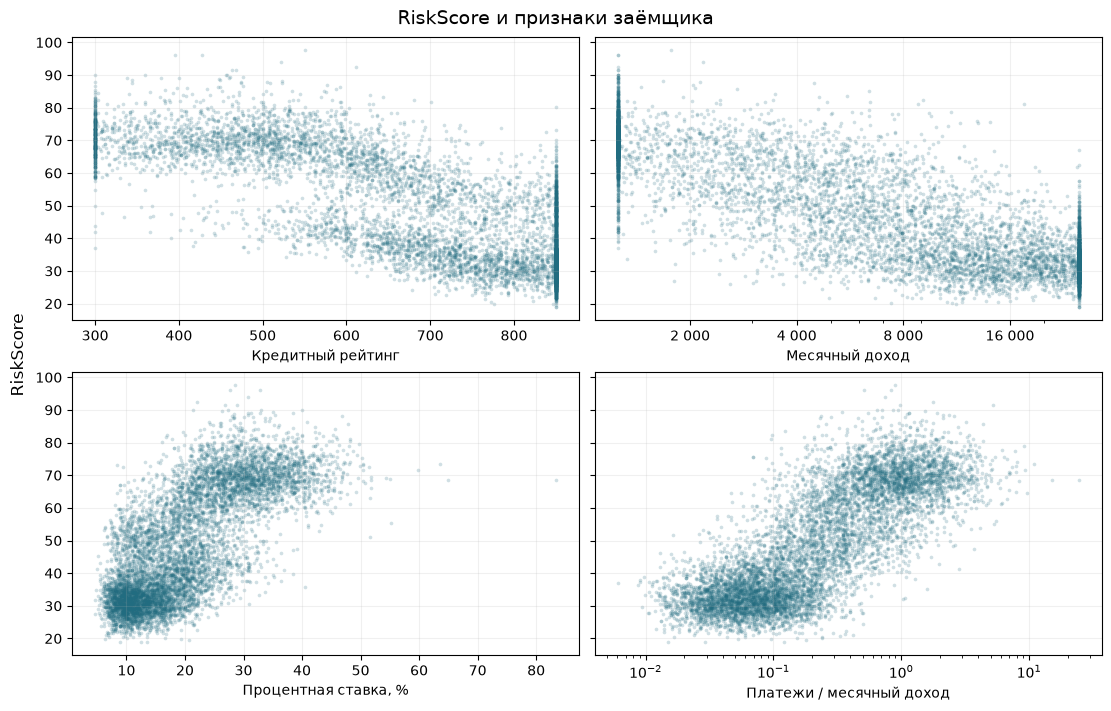

In [11]:
from matplotlib.ticker import NullFormatter

target_plots = [
    ("CreditScore", "Кредитный рейтинг", "linear"),
    ("MonthlyIncome", "Месячный доход", "log"),
    ("InterestRate", "Процентная ставка, %", "linear"),
    ("TotalDebtToIncomeRatio", "Платежи / месячный доход", "log"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True, layout="constrained")
for ax, (column, label, scale) in zip(axes.flat, target_plots):
    values = X_dev[column] * 100 if column == "InterestRate" else X_dev[column]
    ax.scatter(values, y_dev, s=7, alpha=.21, linewidths=0, color="#216c80")
    ax.set(xlabel=label, xscale=scale)
    if column == "MonthlyIncome":
        ax.set_xticks([2000, 4000, 8000, 16000], ["2 000", "4 000", "8 000", "16 000"])
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(alpha=.18)
fig.supylabel("RiskScore")
fig.suptitle("RiskScore и признаки заёмщика", fontsize=14)
plt.show()

### Как модель учитывает сочетания признаков

Сравниваю представления признаков на одинаковых строках. Базовый набор содержит исходные признаки. Второй — прежний вариант с произведениями до третьей степени и индикаторами диапазонов. Третий сохраняет финансовые отношения и заменяет полиномиальные произведения кусочно-линейными функциями.

Для третьего набора вычисляю индекс из годового дохода, суммы кредита, капитала, ставки и долговой нагрузки с поправками на кредитную историю. Для пяти перекрывающихся диапазонов считаю, насколько заявка вошла в диапазон (от 0 до 1). Эту величину умножаю на отдельные признаки. Так, одинаковое увеличение суммы кредита может дать разную прибавку к RiskScore при разном доходе. Коэффициенты и границы самого индекса выбраны в экспериментах на выборке разработки. Индекс служит признаком для регрессии, все веса финального прогноза обучаются через МНК с L2-штрафом.

Из формулы аннуитетного платежа восстанавливаю сумму кредита. Суммарная долговая нагрузка, умноженная на месячный доход, за вычетом платежа по новой заявке даёт текущие ежемесячные платежи. На обучающих данных также выполняется равенство BaseInterestRate = 0,465 − 0,0005 × CreditScore + 0,000001 × LoanAmount + LoanDuration / 1200. Если базовой ставки нет, фактическая ставка даёт приблизительную оценку рейтинга. Исходные заполненные значения сохраняются.

In [12]:
from sklearn.preprocessing import PolynomialFeatures


def recover_financial_values(frame):
    result = frame.copy()
    monthly_rate = frame.InterestRate / 12
    factor = -np.expm1(-frame.LoanDuration * np.log1p(monthly_rate)) / monthly_rate
    principal = frame.MonthlyLoanPayment * factor
    monthly_debt = frame.MonthlyIncome * frame.TotalDebtToIncomeRatio - frame.MonthlyLoanPayment
    result["LoanAmount"] = frame.LoanAmount.fillna(principal)
    result["MonthlyDebtPayments"] = frame.MonthlyDebtPayments.fillna(monthly_debt)
    # При отсутствующей базовой ставке фактическая ставка даёт только приближение.
    result["BaseInterestRate"] = frame.BaseInterestRate.fillna(frame.InterestRate)
    credit = (.465 + 1e-6 * result.LoanAmount + frame.LoanDuration / 1200 - result.BaseInterestRate) / .0005
    result["CreditScore"] = frame.CreditScore.fillna(credit.clip(300, 850))
    return result


def polynomial_terms(frame):
    """Фиксированные функции признаков. Все обучаемые коэффициенты остаются линейными."""
    credit = frame.CreditScore
    income = frame.MonthlyIncome
    burden = frame.TotalDebtToIncomeRatio
    rate = frame.InterestRate
    worth = frame.NetWorth
    core = pd.DataFrame({
        "рейтинг": (credit.fillna(650).clip(300, 850) - 600) / 200,
        "лог дохода": np.log(income / 5000),
        "лог капитала": np.log1p(worth.fillna(50000).clip(lower=0)) / 3 - 3.5,
        "нагрузка": np.log1p(3 * burden.clip(upper=6)),
        "долг к доходу": 3 * frame.DebtToIncomeRatio,
        "ставка": 5 * rate.clip(upper=.55),
        "кредитная история": frame.LengthOfCreditHistory / 15 - 1,
        "банкротство": frame.BankruptcyHistory.fillna(0),
    }, index=frame.index)
    poly = PolynomialFeatures(degree=3, include_bias=False)
    return pd.DataFrame(poly.fit_transform(core), columns=poly.get_feature_names_out(core.columns),
                            index=frame.index).add_prefix("произведение: ")


def repayment_basis(frame):
    """Кусочно-линейный базис по сочетанию суммы кредита, дохода и капитала."""
    income = 12 * frame.MonthlyIncome / 60000 - 1
    principal = frame.LoanAmount / 25000 - 1
    capital = frame.NetWorth.fillna(40000) / 150000
    credit = (frame.CreditScore - 650) / 100
    burden = frame.TotalDebtToIncomeRatio.clip(upper=10)
    debt_ratio = (frame.DebtToIncomeRatio - .30) * 5
    history = (frame.LengthOfCreditHistory - 15) / 10
    bankruptcy = frame.BankruptcyHistory.fillna(.05)
    edu = frame.EducationLevel.map({"High School": 0, "Associate": 1, "Bachelor": 2,
                                     "Master": 3, "Doctorate": 4}).fillna(1).astype(float) - 1
    employed = (frame.EmploymentStatus == "Employed").astype(float)
    # Шкала задаёт направление разбиения. Веса итогового прогноза обучает Ridge.
    margin = (income - .8 * principal + .22 * capital + .13 * credit - .55 * burden
              - .15 * debt_ratio - .8 * bankruptcy - .2 * frame.PreviousLoanDefaults
              + .12 * history + .1 * edu + .15 * employed + 4 * (.12 - frame.InterestRate))
    numeric = pd.DataFrame({"доход": income, "кредит": principal, "капитал": capital,
                            "рейтинг": credit, "нагрузка": burden, "долг": debt_ratio,
                            "история": history, "банкротство": bankruptcy,
                            "дефолт": frame.PreviousLoanDefaults, "образование": edu,
                            "занятость": employed, "собственник": (frame.HomeOwnershipStatus == "Own").astype(float),
                            "карта": (frame.CreditCardUtilizationRate - .3) * 4,
                            "срок": (frame.LoanDuration - 48) / 24})
    parts = []
    for knot in (-1.8, -.9, 0., .9, 1.8):
        level = ((margin - knot) / 1.6).clip(0, 1)
        parts.append(level.rename(f'диапазон {knot}'))
        parts.append(numeric.mul(level, axis=0).add_prefix(f'диапазон {knot} × '))
    return pd.concat(parts, axis=1)


def financial_basis(frame, basis):
    income = frame.MonthlyIncome
    worth = frame.NetWorth
    # На каждом диапазоне свой наклон. Границы заданы в исходных единицах.
    bands = {
        "CreditScore": [300, 450, 550, 625, 675, 725, 775, 850],
        "MonthlyIncome": [1250, 2000, 3000, 4500, 6500, 10000, 15000, 25000],
        "TotalDebtToIncomeRatio": [0, .08, .2, .35, .5, .75, 1.2, 3],
        "InterestRate": [.05, .11, .15, .2, .25, .32, .45, .65],
        "NetWorth": [1000, 10000, 30000, 50000, 100000, 200000, 400000, 1000000],
    }
    extra = {}
    for name, knots in bands.items():
        for left, right in zip(knots, knots[1:]):
            extra[f"{name} [{left}, {right}]"] = ((frame[name]-left)/(right-left)).clip(0, 1).fillna(0)
    thresholds = {"DebtToIncomeRatio": [.15, .2, .25, .3, .35, .4, .5],
                  "CreditCardUtilizationRate": [.3, .4, .5],
                  "LengthOfCreditHistory": [5, 10, 15, 20],
                  "NetWorth": [10000, 50000, 100000, 200000],
                  "CreditScore": [600, 650, 700, 750], "InterestRate": [.1, .2, .3],
                  "TotalDebtToIncomeRatio": [.3, .4, .5]}
    for name, levels in thresholds.items():
        for level in levels:
            extra[f"{name} ≥ {level}"] = (frame[name] >= level).astype(float)
    ratios = {
        "кредит к доходу": np.log1p(frame.LoanAmount / (12 * income)),
        "платёж к доходу": np.log1p(frame.MonthlyLoanPayment / income),
        "текущий долг к доходу": np.log1p(frame.MonthlyDebtPayments / income),
        "обязательства к активам": np.log1p(frame.TotalLiabilities / frame.TotalAssets),
        "кредит к капиталу": np.log1p(frame.LoanAmount / worth),
        "лог стажа": np.log1p(frame.LengthOfCreditHistory),
        "обязательства к доходу": np.log1p(frame.TotalLiabilities / (12 * income)),
        "сбережения к кредиту": np.log1p(frame.SavingsAccountBalance / frame.LoanAmount),
    }
    ratio_knots = {
        "кредит к доходу": [.05, .15, .3, .6, 1.2], "платёж к доходу": [.05, .15, .3, .6, 1.2],
        "текущий долг к доходу": [.05, .15, .3, .6, 1.2],
        "обязательства к активам": [.1, .3, .7, 1., 1.5],
        "кредит к капиталу": [.1, .3, .6, 1., 1.5], "лог стажа": [1.5, 2, 2.5, 3, 3.25],
    }
    for name, values in ratios.items():
        values = values.fillna(0)
        extra[name] = values
        for knot in ratio_knots.get(name, []):
            extra[f"{name} выше {knot}"] = (values - knot).clip(lower=0)
    if basis == "polynomial":
        terms = polynomial_terms(frame)
    elif basis == "capacity":
        terms = repayment_basis(frame)
    else:
        raise ValueError(f"Неизвестный набор признаков: {basis}")
    return pd.concat([terms, pd.DataFrame(extra, index=frame.index)], axis=1)

# Проверяем связи на доступных исходных данных выборки разработки.
known = X_dev.dropna().copy()
masked = known.copy()
masked[["LoanAmount", "MonthlyDebtPayments", "CreditScore"]] = np.nan
restored = recover_financial_values(masked)
for col in ("LoanAmount", "MonthlyDebtPayments", "CreditScore"):
    np.testing.assert_allclose(restored[col], known[col], rtol=1e-9, atol=1e-6)
print("Для заполненных заявок с известной базовой ставкой три формулы воспроизводят исходные значения.")

Для заполненных заявок с известной базовой ставкой три формулы воспроизводят исходные значения.


### Финансовый профиль для прогноза RiskScore

Одна и та же сумма кредита создаёт разную нагрузку для заёмщиков с разным доходом. Сначала вычисляю непрерывный индекс из наблюдаемых признаков, включая размер кредита, капитал, ставку и долю ежемесячных платежей в доходе. Затем создаю числовые столбцы для диапазонов дохода, рейтинга и использования кредитной карты. Например, заявка с доходом 85 000 пересекает три границы годового дохода — 30 000, 50 000 и 80 000. Веса этих трёх столбцов определяет регрессия. Несколько плавных переходов позволяют ей учитывать сочетания признаков. Функция `ndtr` здесь переводит число в диапазон от нуля до единицы. Её значение имеет смысл веса признака.

Параметры преобразований подобраны по размеченной выборке разработки и зафиксированы для сравнения. В таблице ниже отдельно проверяются профиль и профиль с дополнительными произведениями признаков. Прогноз представляет собой взвешенную сумму получившихся столбцов. Её коэффициенты оценивает одна линейная регрессия с L2-штрафом.

В части обучающих анкет одновременно пропущены девять полей. Сумма кредита и текущий платёж восстанавливаются из финансовых равенств. Для оставшихся неопределённых величин использую 21 фиксированный сценарий активов, ставки и истории банкротства. Константы приближают распределения, наблюдавшиеся на выборке разработки. Усредняются значения признаков одной строки. Для полной анкеты преобразование выполняется один раз.

В новой версии группирую границы по шести шкалам. Например, при доходе 85 000 получается одно значение 3 по шкале дохода. Учитываю отношение платежей к доходу, а также величину кредита относительно капитала. Плавный коэффициент меняет вклад каждой шкалы. Формулы и их константы подобраны в экспериментах на разработке. На выходе получается 11 числовых признаков для одной линейной регрессии с L2-штрафом.

In [13]:
from scipy.special import ndtr, ndtri

def risk_profile(frame, interactions=False, grouped=False):
    """Фиксированные числовые признаки одной заявки для линейной регрессии."""
    income = (12 * frame.MonthlyIncome / 100000).clip(0, 10)
    loan = (frame.LoanAmount / 30000).clip(0, 10)
    wealth = (frame.NetWorth.fillna(75000) / 200000).clip(0, 10)
    credit = (frame.CreditScore - 650) / 100
    rate = 10 * (frame.InterestRate - .20)
    burden = frame.TotalDebtToIncomeRatio.clip(0, 10)
    term = (frame.LoanDuration - 48) / 36
    history = (frame.LengthOfCreditHistory - 15) / 10
    card = 5 * (frame.CreditCardUtilizationRate - .30)
    bankruptcy = frame.BankruptcyHistory.fillna(.05)
    default = frame.PreviousLoanDefaults
    unemployed = (frame.EmploymentStatus == "Unemployed").astype(float)
    education = frame.EducationLevel.map({"High School": 0, "Associate": 1, "Bachelor": 2,
                                          "Master": 3, "Doctorate": 4}).fillna(1) - 1
    age = frame.Age
    payments = (frame.PaymentHistory - 24) / 5
    utilities = 5 * (frame.UtilityBillsPaymentHistory - .8)
    # Константы подобраны на выборке разработки и фиксируются до проверки на отложенной части.
    capacity = (-.26 + .66*income - .20*loan + .25*wealth - .26*credit - .62*rate
                - 1.09*burden - .45*bankruptcy - .08*default + .085*history + .055*card
                - .17*unemployed + .067*education + .03*payments + .03*utilities
                + .02*(age-40)/15 + .03*term)
    capacity += (.105*age.between(30,55) - .10*(frame.InterestRate >= .20)
                 + .065*frame.CreditScore.between(675,799) - .018*(frame.NumberOfCreditInquiries-1)
                 - .012*(frame.NumberOfDependents-2) + .035*(frame.HomeOwnershipStatus == "Own") - .055)
    capacity += (.055*(frame.Experience >= 20) - .050*(age >= 55) - .07*(burden >= .2)
                 - .055*(frame.LoanDuration >= 72) + .05*(frame.LoanAmount >= .4*12*frame.MonthlyIncome)
                 - .06*(frame.LoanPurpose == "Auto") - .04*(frame.HomeOwnershipStatus == "Rent")
                 - .035*(frame.EducationLevel == "Master") + .045*(frame.EducationLevel == "Doctorate") + .055)
    if interactions:
        debt = 5 * (frame.DebtToIncomeRatio - .25)
        capacity += (.05*(np.log1p(3*burden)-.5)*debt + .03*(wealth-.5).clip(-1,3)**2
                     + .025*rate.clip(-1,2)**2 - .03*((age-40)/15)*education
                     + .025*(wealth-.5).clip(-1,3)*(np.log(loan)+term))
    if grouped:
        return grouped_profile(frame, capacity)
    columns = {
        "банкротство": bankruptcy, "дефолт": default, "безработица": unemployed,
        "самозанятость": (frame.EmploymentStatus == "Self-Employed").astype(float),
        "карта": card, "история": history, "нагрузка": burden, "доход": income,
        "ставка": rate, "рейтинг": credit, "капитал": wealth, "кредит": loan,
        "лог капитала": np.log1p(frame.NetWorth.fillna(75000) / 200000),
        "лог дохода": np.log(income), "доля долга": frame.DebtToIncomeRatio,
        "история до 15 лет": history.clip(upper=0), "история до 5 лет": history.clip(upper=-1),
        "доход до 120 тыс.": income.clip(upper=1.2), "капитал до 400 тыс.": wealth.clip(upper=2),
        "нагрузка до 50%": burden.clip(upper=.5),
    }
    levels = {"годовой доход": (12*frame.MonthlyIncome, [30000,50000,80000,120000]),
              "кредитный рейтинг": (frame.CreditScore, [600,650,700,750]),
              "капитал": (frame.NetWorth, [50000,100000,250000,500000,1000000]),
              "доля долга": (frame.DebtToIncomeRatio, [.2,.3,.4,.5]),
              "использование карты": (frame.CreditCardUtilizationRate, [.2,.4,.6,.8]),
              "длительность истории": (frame.LengthOfCreditHistory, [3,5,7,10,15,20])}
    for name, (values, thresholds) in levels.items():
        for threshold in thresholds:
            columns[f"{name} ≥ {threshold}"] = (values >= threshold).astype(float)
    width = .29
    level = ndtr(capacity / width)
    result = pd.DataFrame(columns, index=frame.index).mul(1 - .30*level, axis=0)
    for center in (-.5, -.25, 0, .25, .5):
        result[f"плавный переход {center}"] = ndtr((capacity-center) / width)
    return result


def scorecard_fields(frame):
    income = 12 * frame.MonthlyIncome
    bankrupt = frame.BankruptcyHistory.fillna(.05)
    employed = (frame.EmploymentStatus == "Employed").astype(float)
    scales = {
        "рейтинг": (frame.CreditScore, [600, 650, 700, 750]),
        "доход": (income, [30000, 50000, 80000, 120000]),
        "капитал": (frame.NetWorth, [50000, 100000, 250000, 500000, 1000000]),
        "история": (frame.LengthOfCreditHistory, [3, 5, 7, 10]),
        "долг": (frame.DebtToIncomeRatio, [.2, .3, .4, .5]),
        "карта": (frame.CreditCardUtilizationRate, [.2, .4, .6, .8]),
    }
    counts = pd.DataFrame({name: sum((values >= boundary).astype(float) for boundary in boundaries)
                           for name, (values, boundaries) in scales.items()}, index=frame.index)
    points = (74 - 4 * counts["рейтинг"] - 2.5 * counts["доход"] - 2 * counts["капитал"]
              - counts["история"] + 2.2 * counts["долг"] + 1.4 * counts["карта"]
              + 13.5 * bankrupt + 2.8 * frame.PreviousLoanDefaults - 3.1 * employed)
    counts["банкротство"] = bankrupt
    counts["дефолты"] = frame.PreviousLoanDefaults
    counts["занятость"] = employed
    return counts, points


def grouped_profile(frame, capacity):
    """Один балл за каждую пересечённую границу внутри финансовой шкалы."""
    income = 12 * frame.MonthlyIncome
    wealth = frame.NetWorth.fillna(55000)
    duration = (frame.LoanDuration - 48) / 36
    lines = (frame.NumberOfOpenCreditLines - 3) / 2
    rate = 10 * (frame.InterestRate - .2)
    rating = (frame.CreditScore - 650) / 100
    card = 5 * (frame.CreditCardUtilizationRate - .3)
    bankrupt = frame.BankruptcyHistory.fillna(.05)
    share = np.log((frame.LoanAmount / 30000) / (income / 100000)).clip(-2.5, 3)
    saving = np.log(frame.SavingsAccountBalance / 3000).clip(-2, 3)
    payments = ((frame.PaymentHistory - 24) / 5).clip(-2, 3)
    employed = (frame.EmploymentStatus == "Employed").astype(float)

    # Отдельно учитываем размер кредита и долю дохода, которая уходит на платежи.
    history_shift = (
        -.10 * (frame.CreditCardUtilizationRate >= .6) - .10 * (frame.TotalDebtToIncomeRatio >= .8)
        - .095 * bankrupt * share - .060 * (frame.MaritalStatus == "Widowed")
        + .04 * (frame.NumberOfCreditInquiries >= 2) + .034 * lines.clip(-2.5, 3) * rate.clip(-2.5, 3)
        - .03 * (frame.CreditScore >= 780) + .025 * (frame.LoanAmount >= .15 * income)
        + .025 * duration.clip(-2, 3)**2 - .02 * saving**2 - .02 * payments**2
        + .015 * lines.clip(-2, 3)**2 + .017 * duration + .012 * np.log1p(.15 * wealth / frame.LoanAmount).clip(-4, 4)
    )
    monthly = frame.MonthlyIncome
    budget_shift = (
        .055 * (income >= 45000) - .032 * (income >= 30000) - .055 * (frame.MonthlyLoanPayment >= .25 * monthly)
        - .025 * (frame.MonthlyDebtPayments >= .15 * monthly) + .065 * (frame.MonthlyDebtPayments >= .50 * monthly)
        + .035 * (frame.CreditScore >= 650) + .035 * (frame.CreditScore >= 800) + .04 * (wealth >= 5000)
        - .025 * (wealth >= .50 * income) - .030 * (wealth / 200000).clip(upper=4) + .040 * duration
        + .045 * bankrupt - .042 * frame.PreviousLoanDefaults + .040 * (frame.EmploymentStatus == "Unemployed")
        + .014 * lines - .018 * rating - .015 * card - .023 * (frame.HomeOwnershipStatus == "Own") - .05
    )
    level = ndtr((capacity + .65 * history_shift + .55 * budget_shift - .055) / .31)
    counts, points = scorecard_fields(frame)
    multiplier = 1 - .30 * level
    return pd.concat([(points * multiplier).rename("суммарный балл"), level.rename("переход"),
                      counts.mul(multiplier, axis=0)], axis=1)



def profile_features(frame, interactions=False, credit_missing=None, grouped=False, encoder=None):
    """При совместном пропуске усредняем признаки по 21 фиксированному сценарию."""
    if encoder is None:
        encoder = lambda data: risk_profile(data, interactions, grouped)
    values = encoder(frame)
    missing = frame.NetWorth.isna() & frame.BankruptcyHistory.isna()
    if not missing.any():
        return values
    if credit_missing is None:
        credit_missing = frame.CreditScore.isna()
    subset = frame.loc[missing]
    n = 21
    order = np.arange(n)
    assets = np.exp(np.log(61000) + 1.28*ndtri((order+.5)/n))
    rate_factors = np.clip(1 + .1*ndtri(((8*order % n)+.5)/n), .8, 1.2)
    total = np.zeros((len(subset), values.shape[1]))
    for j in order:
        scenario = subset.copy()
        balance = assets[j] - subset.TotalLiabilities
        scenario["NetWorth"] = balance.where(balance > 0, 6000)
        scenario["BankruptcyHistory"] = float(j == n//2)
        estimated_credit = (.465 + 1e-6*subset.LoanAmount + subset.LoanDuration/1200
                            - subset.InterestRate/rate_factors[j]) / .0005
        scenario["CreditScore"] = subset.CreditScore.where(~credit_missing.loc[missing],
                                                         estimated_credit.clip(300, 850))
        total += encoder(scenario).to_numpy()
    values.loc[missing] = total / n
    return values


## 6. Выбор модели и время проверки

На выборке разработки сравниваю обычный МНК и регуляризацию по пяти фолдам с одинаковым разбиением. Три значения силы штрафа позволяют увидеть, помогает ли прижатие весов к нулю. Для произвольного Lp здесь беру $p=1.5$, степень можно поменять переменной `P`. Выбираю модель по MSE на прогнозах вне обучавшего фолда (OOF). Условия для признаков исследованы на выборке разработки. Поэтому её OOF-ошибка служит для выбора варианта и может быть оптимистичной. При выборе модели метрики отложенных 20% не используются.

In [14]:
P = 1.5
candidates = {"МНК": {}}
for alpha in (.001, .01, .1):
    candidates.update({
        f"L1 λ={alpha}": {"l1": alpha},
        f"L2 λ={alpha}": {"lp": alpha},
        f"Elastic Net λ={alpha}": {"l1": alpha/2, "lp": alpha/2},
        f"Lp p={P}, λ={alpha}": {"lp": alpha, "p": P},
    })


expanded_candidates = {f"Расширенные признаки · L2 λ={a}": {"lp": a}
                       for a in (.0001, .001, .005, .02)}
capacity_candidates = {f"Диапазоны нагрузки · L2 λ={a}": {"lp": a}
                       for a in (.0005, .003, .012, .04)}
profile_candidates = {
    f"Финансовый профиль{suffix} · L2 λ={a}": (basis, {"lp": a})
    for basis, suffix in [("profile", ""), ("profile_interactions", " со взаимодействиями")]
    for a in (.0001, .002, .012)
}
profile_candidates["Групповые шкалы · L2 λ=0.002"] = ("grouped", {"lp": .002})
candidate_basis = dict.fromkeys(candidates, "base")
candidate_basis.update(dict.fromkeys(expanded_candidates, "polynomial"))
candidate_basis.update(dict.fromkeys(capacity_candidates, "capacity"))
for name, (basis, settings) in profile_candidates.items():
    candidate_basis[name] = basis
    candidates[name] = settings
candidates.update(expanded_candidates)
candidates.update(capacity_candidates)


def candidate_model(name):
    return MyLinearRegression() if name == "МНК" else RegularizedRegression(**candidates[name])


oof = {name: np.empty(len(dev)) for name in candidates}
fold_mse = {name: [] for name in candidates}
ols_seconds = 0.
for tr, va in kfold_indices(len(dev), k=5):
    start = perf_counter()
    A, B = prepare(X_dev.iloc[tr], X_dev.iloc[va])
    prep_seconds = perf_counter() - start
    matrices = {"base": (A, B)}
    for basis in ("polynomial", "capacity", "profile", "profile_interactions", "grouped"):
        matrices[basis] = prepare(X_dev.iloc[tr], X_dev.iloc[va], basis=basis)
    for name in candidates:
        fold_A, fold_B = matrices[candidate_basis[name]]
        start = perf_counter()
        pred = candidate_model(name).fit(fold_A, y_dev[tr]).predict(fold_B)
        if name == "МНК":
            ols_seconds += prep_seconds + perf_counter() - start
        oof[name][va] = pred
        fold_mse[name].append(mse(y_dev[va], pred))

cv_table = pd.DataFrame({name: {**scores(y_dev, oof[name]),
                                "Разброс MSE по фолдам (σ)": np.std(fold_mse[name])}
                         for name in candidates}).T.sort_values("MSE")
winner = cv_table.index[0]
display(cv_table)
print("Выбранная по пяти фолдам модель:", winner)
print("MSE МНК по отдельным фолдам:", np.round(fold_mse["МНК"], 4))

start = perf_counter()
loo = loo_ols(X_dev, y_dev)
loo_seconds = perf_counter() - start
display(pd.DataFrame([{"Метод проверки": "5-fold", **scores(y_dev, oof["МНК"]), "Секунды": ols_seconds},
                      {"Метод проверки": "LOO (PRESS)", **scores(y_dev, loo), "Секунды": loo_seconds}
                     ]).set_index("Метод проверки"))
print("Обе строки относятся к обычной линейной регрессии на одной выборке разработки.")

dev_complete = X_dev.notna().all(axis=1).to_numpy()
display(pd.DataFrame([
    {"Группа разработки": name, "Строк": int(mask.sum()), **scores(y_dev[mask], oof[winner][mask])}
    for name, mask in [("Все заявки", np.ones(len(dev), dtype=bool)), ("Без пропусков", dev_complete),
                       ("С пропусками", ~dev_complete)]
]).set_index("Группа разработки"))

,MSE,MAE,R²,"MAPE, %",Разброс MSE по фолдам (σ)
Групповые шкалы · L2 λ=0.002,18.61615,2.95697,0.93693,6.86532,0.75884
Финансовый профиль со взаимодействиями · L2 λ=0.002,19.05258,3.00634,0.93546,6.98441,0.59978
Финансовый профиль со взаимодействиями · L2 λ=0.0001,19.06173,2.99885,0.93542,6.96752,0.61749
Финансовый профиль со взаимодействиями · L2 λ=0.012,19.09461,3.02912,0.93531,7.03769,0.54038
Финансовый профиль · L2 λ=0.002,19.14941,3.01231,0.93513,6.99432,0.66385
Финансовый профиль · L2 λ=0.0001,19.16087,3.00518,0.93509,6.97842,0.68669
Финансовый профиль · L2 λ=0.012,19.18861,3.03447,0.93499,7.04550,0.59624
Диапазоны нагрузки · L2 λ=0.003,21.11272,3.24458,0.92848,7.50325,0.60573
Диапазоны нагрузки · L2 λ=0.0005,21.15331,3.24036,0.92834,7.49314,0.66085
Диапазоны нагрузки · L2 λ=0.012,21.15871,3.25936,0.92832,7.53744,0.54927


Выбранная по пяти фолдам модель: Групповые шкалы · L2 λ=0.002
MSE МНК по отдельным фолдам: [54.7836 51.6281 51.7636 50.3042 52.5159]


,MSE,MAE,R²,"MAPE, %",Секунды
Метод проверки,,,,,
5-fold,52.19910,5.78264,0.82317,13.59539,0.55282
LOO (PRESS),52.09138,5.77989,0.82353,13.59426,0.11306


Обе строки относятся к обычной линейной регрессии на одной выборке разработки.


,Строк,MSE,MAE,R²,"MAPE, %"
Группа разработки,,,,,
Все заявки,7830,18.61615,2.95697,0.93693,6.86532
Без пропусков,7464,17.00240,2.85847,0.94245,6.65054
С пропусками,366,51.52603,4.96586,0.82262,11.24532


### Как сила штрафа влияет на ошибку и веса

На первом графике показан MSE на прогнозах пяти фолдов. На втором — евклидова норма коэффициентов модели, обученной на всей выборке разработки. Сравнение использует те же исходные признаки и те же значения λ, что и в таблице выше.

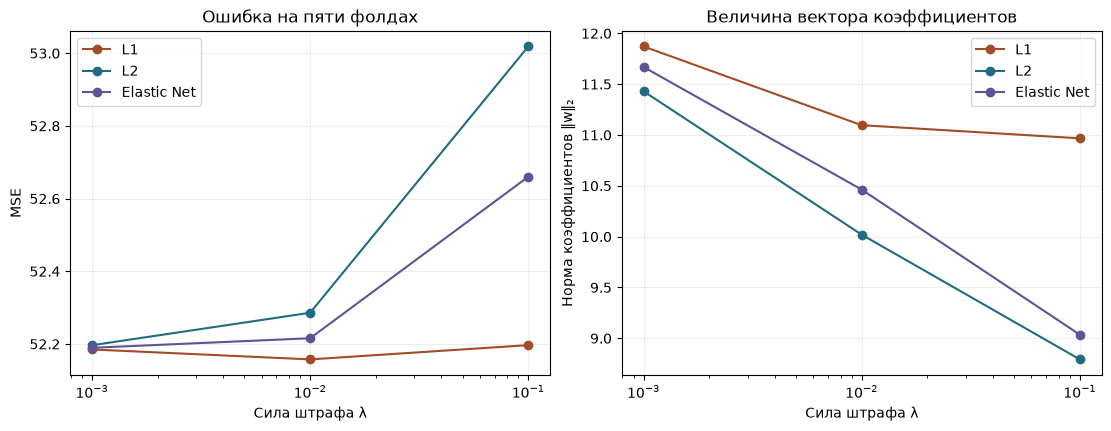

In [15]:
penalty_strengths = (.001, .01, .1)
regularization_x = Features().fit(X_dev).transform(X_dev)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for penalty, color in [("L1", "#a04d28"), ("L2", "#216c80"), ("Elastic Net", "#645094")]:
    names = [f"{penalty} λ={strength}" for strength in penalty_strengths]
    errors = cv_table.loc[names, "MSE"].to_numpy()
    norms = [
        np.linalg.norm(candidate_model(name).fit(regularization_x, y_dev).coef_)
        for name in names
    ]
    for ax, values in zip(axes, (errors, norms)):
        ax.plot(penalty_strengths, values, marker="o", label=penalty, color=color)
axes[0].set(title="Ошибка на пяти фолдах", ylabel="MSE")
axes[1].set(title="Величина вектора коэффициентов", ylabel="Норма коэффициентов ‖w‖₂")
for ax in axes:
    ax.set(xlabel="Сила штрафа λ", xscale="log")
    ax.grid(alpha=.2)
    ax.legend()
plt.show()

### Проверка на других разбиениях

С фиксированными настройками повторяю парное сравнение с прежней версией. Оба алгоритма получают один и тот же набор строк в каждом фолде.

In [16]:
previous = "Финансовый профиль со взаимодействиями · L2 λ=0.002"
comparison = []
for seed in (SEED, 17, 73):
    results = {}
    for name in (previous, winner):
        if seed == SEED:
            fold_errors = fold_mse[name]
            predictions = oof[name]
        else:
            predictions = np.empty(len(dev))
            fold_errors = []
            for tr, va in kfold_indices(len(dev), k=5, seed=seed):
                A, B = prepare(X_dev.iloc[tr], X_dev.iloc[va], basis=candidate_basis[name])
                predictions[va] = candidate_model(name).fit(A, y_dev[tr]).predict(B)
                fold_errors.append(mse(y_dev[va], predictions[va]))
        results[name] = (mse(y_dev, predictions), np.asarray(fold_errors))
    old_error, old_by_fold = results[previous]
    new_error, new_by_fold = results[winner]
    comparison.append({"Разбиение (seed)": seed, "Предыдущий MSE": old_error,
                       "Новый MSE": new_error, "Снижение MSE": old_error - new_error,
                       "Фолдов с улучшением из 5": int(np.sum(new_by_fold < old_by_fold))})
display(pd.DataFrame(comparison).set_index("Разбиение (seed)"))

,Предыдущий MSE,Новый MSE,Снижение MSE,Фолдов с улучшением из 5
Разбиение (seed),,,,
42,19.05258,18.61615,0.43643,5
17,19.05376,18.66121,0.39255,5
73,19.01263,18.65760,0.35503,5


## 7. Проверка на отложенных данных

Для трёх собственных способов обучения показываю качество на одинаковых строках. Эталон sklearn для точного решения — `LinearRegression`. Для стохастического метода дополнительно обучаю `SGDRegressor` без штрафа и с усреднением. Разная последовательность случайных обновлений даёт небольшие расхождения. Прогноз средним обучающей части показывает, сколько выигрывает регрессия относительно простейшего решения.

Первый вариант расширенных признаков дал MSE 25,05 на отложенной части. После этого уточнил обработку пропусков. Для выбора коэффициента штрафа и сравнения вариантов использовал только фолды выборки разработки. Итоговый расчёт ниже повторно использует тот же holdout, независимая внешняя проверка — результат Kaggle.

Следующие таблицы воспроизводят сравнение первых двух версий. Для третьей посылки протокол и результаты приведены в следующем разделе.

In [17]:
A, B = prepare(X_dev, X_hold)
models = {
    "Своя · аналитическая": MyLinearRegression(),
    "Своя · GD": MyLinearRegression("gd", epochs=12000),
    "Своя · SGD": MyLinearRegression("sgd", epochs=120),
    "sklearn · LinearRegression": LinearRegression(),
    "sklearn · SGDRegressor": SGDRegressor(
        penalty=None, alpha=.0001, learning_rate="invscaling", eta0=.005,
        average=True, max_iter=150, tol=None, random_state=SEED),
}
hold_predictions = {}
rows = {}
for name, model in models.items():
    start = perf_counter()
    hold_predictions[name] = model.fit(A, y_dev).predict(B)
    rows[name] = {**scores(y_hold, hold_predictions[name]), "Секунды": perf_counter() - start}
reference_prediction = hold_predictions["sklearn · LinearRegression"]
for name in models:
    rows[name]["MAE к прогнозу sklearn OLS"] = mae(reference_prediction, hold_predictions[name])
rows["Среднее на train"] = scores(y_hold, np.full(len(y_hold), y_dev.mean()))
display(pd.DataFrame(rows).T)
np.testing.assert_allclose(hold_predictions["Своя · аналитическая"], reference_prediction,
                           rtol=1e-7, atol=1e-6)

# Повторяем аналитическое обучение при min-max масштабировании.
A_min, B_min = prepare(X_dev, X_hold, method="min-max")
minmax_prediction = MyLinearRegression().fit(A_min, y_dev).predict(B_min)
print(f"MSE при min-max: {mse(y_hold, minmax_prediction):.5f}; "
      f"при z-score: {mse(y_hold, reference_prediction):.5f}.")

,MSE,MAE,R²,"MAPE, %",Секунды,MAE к прогнозу sklearn OLS
Своя · аналитическая,55.68433,5.95837,0.81685,13.95843,0.01188,0.00000
Своя · GD,55.69842,5.95904,0.81680,13.95921,0.06632,0.02002
Своя · SGD,55.75282,5.96118,0.81662,13.95883,2.68199,0.13909
sklearn · LinearRegression,55.68433,5.95837,0.81685,13.95843,0.01574,0.00000
sklearn · SGDRegressor,55.68460,5.96411,0.81685,13.95650,0.22188,0.10726
Среднее на train,304.11215,15.65908,-0.00025,36.55197,NaN,NaN


MSE при min-max: 55.68433; при z-score: 55.68433.


### Сходимость GD и SGD

Сравниваю обучающий MSE итерационных методов с минимумом аналитического МНК на тех же стандартизированных признаках. У GD шаг использует всю выборку. Для SGD одна точка соответствует концу эпохи и показывает ошибку текущих весов до их финального усреднения. Шкалы MSE подобраны отдельно для каждой панели. Замеры времени выше сделаны без записи истории обучения.

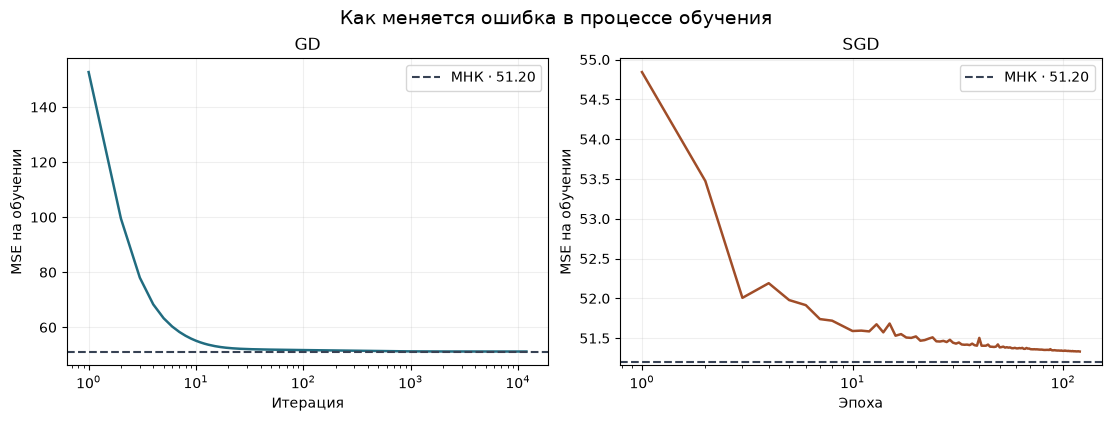

In [18]:
train_ols_mse = mse(y_dev, models["Своя · аналитическая"].predict(A))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
for ax, method, label, axis_label, color in zip(
    axes, ("gd", "sgd"), ("GD", "SGD"), ("Итерация", "Эпоха"), ("#216c80", "#a04d28"),
):
    epochs = models[f"Своя · {label}"].epochs
    traced = MyLinearRegression(method, epochs=epochs).fit(A, y_dev, track_loss=True)
    np.testing.assert_allclose(traced.coef_, models[f"Своя · {label}"].coef_, atol=1e-10)
    losses = traced.loss_history_
    ax.plot(np.arange(1, len(losses) + 1), losses, color=color, linewidth=1.8)
    ax.axhline(train_ols_mse, linestyle="--", color="#374254", label=f"МНК · {train_ols_mse:.2f}")
    ax.set(title=label, xlabel=axis_label, ylabel="MSE на обучении", xscale="log")
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle("Как меняется ошибка в процессе обучения", fontsize=14)
plt.show()

In [19]:
final_A, final_B = prepare(X_dev, X_hold, basis=candidate_basis[winner])
selected = candidate_model(winner).fit(final_A, y_dev)
selected_pred = selected.predict(final_B)
hold_scores = scores(y_hold, selected_pred)
sk_scores = {"MSE": metrics.mean_squared_error(y_hold, selected_pred),
             "MAE": metrics.mean_absolute_error(y_hold, selected_pred),
             "R²": metrics.r2_score(y_hold, selected_pred),
             "MAPE, %": 100 * metrics.mean_absolute_percentage_error(y_hold, selected_pred)}
np.testing.assert_allclose(list(hold_scores.values()), list(sk_scores.values()))
display(pd.DataFrame({"Своя метрика": hold_scores, "sklearn": sk_scores}))
rmse = np.sqrt(hold_scores["MSE"])
print(f"Модель второй посылки: {winner}. На отложенной части RMSE = {rmse:.2f} единиц RiskScore.")
print(f"При сравнении с порогом 18 локальный запас равен {18 - hold_scores['MSE']:+.3f} MSE.")
print("Официальный результат для допуска выставляет Kaggle по скрытым ответам.")

# В официальном test все признаки заполнены. Смотрим, как пропуски влияют на оценку качества.
complete = X_hold.notna().all(axis=1).to_numpy()
summary = []
for label, mask in [("Все заявки", np.ones(len(y_hold), dtype=bool)),
                    ("Без пропусков", complete), ("С пропусками", ~complete)]:
    summary.append({"Группа": label, "Строк": mask.sum(), **scores(y_hold[mask], selected_pred[mask])})
display(pd.DataFrame(summary).set_index("Группа"))
print(f"Строк в test с пропусками: {test[features].isna().any(axis=1).sum()}.")

old_A, old_B = prepare(X_dev, X_hold, basis=candidate_basis[previous])
old_pred = candidate_model(previous).fit(old_A, y_dev).predict(old_B)
paired = []
for label, mask in [("Все заявки", np.ones(len(y_hold), dtype=bool)), ("Без пропусков", complete)]:
    before, after = mse(y_hold[mask], old_pred[mask]), mse(y_hold[mask], selected_pred[mask])
    paired.append({"Группа": label, "Предыдущий MSE": before, "Новый MSE": after,
                   "Снижение, %": 100 * (before - after) / before})
display(pd.DataFrame(paired).set_index("Группа"))

,Своя метрика,sklearn
MSE,21.06621,21.06621
MAE,3.10349,3.10349
R²,0.93071,0.93071
"MAPE, %",7.10323,7.10323


Модель второй посылки: Групповые шкалы · L2 λ=0.002. На отложенной части RMSE = 4.59 единиц RiskScore.
При сравнении с порогом 18 локальный запас равен -3.066 MSE.
Официальный результат для допуска выставляет Kaggle по скрытым ответам.


,Строк,MSE,MAE,R²,"MAPE, %"
Группа,,,,,
Все заявки,1958,21.06621,3.10349,0.93071,7.10323
Без пропусков,1868,19.54678,3.01500,0.93586,6.90526
С пропусками,90,52.60295,4.94017,0.81816,11.21218


Строк в test с пропусками: 0.


,Предыдущий MSE,Новый MSE,"Снижение, %"
Группа,,,
Все заявки,21.14394,21.06621,0.36758
Без пропусков,19.57375,19.54678,0.13780


In [20]:
# Дополнительный ориентир: каждая из всех очищенных строк получает прогноз вне своего фолда.
# Параметры зафиксированы. При разработке использовалась часть этих заявок.
# Эта оценка дополняет отдельную отложенную выборку и публикуется для всех строк и обоих срезов.
full_oof = np.empty(len(y))
for tr, va in kfold_indices(len(y), k=5, seed=SEED):
    A, B = prepare(X.iloc[tr], X.iloc[va], basis=candidate_basis[winner])
    full_oof[va] = candidate_model(winner).fit(A, y[tr]).predict(B)
full_complete = X.notna().all(axis=1).to_numpy()
full_summary = pd.DataFrame([
    {"Все размеченные заявки, 5 фолдов": label, "Строк": int(mask.sum()), **scores(y[mask], full_oof[mask])}
    for label, mask in [("Все заявки", np.ones(len(y), dtype=bool)), ("Без пропусков", full_complete),
                        ("С пропусками", ~full_complete)]
]).set_index("Все размеченные заявки, 5 фолдов")
display(full_summary)

,Строк,MSE,MAE,R²,"MAPE, %"
"Все размеченные заявки, 5 фолдов",,,,,
Все заявки,9788,19.12318,2.99156,0.93561,6.92817
Без пропусков,9332,17.52831,2.89535,0.94104,6.71732
С пропусками,456,51.76192,4.96035,0.82168,11.24310


## 8. Доработка после двух посылок

У первой версии публичный MSE составил 19,2661695, у второй — 19,4569822. Для третьей версии уменьшен вес вручную заданных поправок и убраны произведения из исходного индекса финансовой нагрузки. Одна линейная регрессия обучает коэффициенты по 13 основным и 12 дополнительным признакам. Дополнительные признаки учитывают доход, капитал, срок и долговую нагрузку в области плавного перехода. Более сильный L2-штраф ограничивает их влияние.

Из прежней отложенной выборки выделены две части с фиксированным seed 34619. Первая использована при выборе версии, вторая просмотрена после фиксации формулы и штрафов. Ранее по этим заявкам уже публиковалась агрегированная метрика. В этом сравнении на всех строках первой и второй частей каждый вариант предсказывает после обучения на исходных 7 830 заявках разработки.

In [21]:
def conservative_profile(frame, record_strength=1., version5=False):
    income = 12 * frame.MonthlyIncome / 100000
    amount = frame.LoanAmount / 30000
    wealth = frame.NetWorth.fillna(75000) / 200000
    credit = (frame.CreditScore - 650) / 100
    rate = 10 * (frame.InterestRate - .20)
    burden = frame.TotalDebtToIncomeRatio
    duration = (frame.LoanDuration - 48) / 36
    bankruptcy = frame.BankruptcyHistory.fillna(.05)
    education = frame.EducationLevel.map({"High School": -1, "Associate": 0, "Bachelor": 1,
                                          "Master": 2, "Doctorate": 3}).fillna(0)
    age_band = frame.Age.between(30, 55).astype(float)
    high_rate = (frame.InterestRate >= .20).astype(float)

    financial = (.66 * income - .20 * amount.clip(upper=10) + .25 * wealth.clip(upper=10)
                 - .26 * credit - .62 * rate - 1.09 * burden.clip(upper=10))
    history = (-.45 * bankruptcy - .08 * frame.PreviousLoanDefaults
               + .085 * (frame.LengthOfCreditHistory - 15) / 10
               + .055 * 5 * (frame.CreditCardUtilizationRate - .30)
               - .17 * (frame.EmploymentStatus == "Unemployed") + .067 * education
               + .03 * (frame.PaymentHistory - 24) / 5 + .15 * (frame.UtilityBillsPaymentHistory - .8)
               + .02 * (frame.Age - 40) / 15 + .03 * duration)
    adjustment = (.105 * age_band - .10 * high_rate + .065 * frame.CreditScore.between(675, 799)
                  - .018 * (frame.NumberOfCreditInquiries - 1) - .012 * (frame.NumberOfDependents - 2)
                  + .035 * (frame.HomeOwnershipStatus == "Own") - .055)
    margin = financial + history + .20 * adjustment - .315
    # У v4 меньше вклад пяти вручную заданных поправок. Коэффициенты регрессии учатся на train.
    individual = (.03 * ((frame.PaymentHistory - 24) / 5).clip(-5, 6)
                  + .03 * (5 * (frame.UtilityBillsPaymentHistory - .8)).clip(-5, 6)
                  + .02 * ((frame.Age - 40) / 15).clip(-5, 6)
                  + .055 * (5 * (frame.CreditCardUtilizationRate - .3)).clip(-5, 6)
                  + .03 * duration.clip(-5, 6))
    margin += (record_strength - 1.) * individual
    if version5:
        default_effect = -.45 * bankruptcy - .08 * frame.PreviousLoanDefaults
        debt_effect = -1.09 * (burden.clip(upper=2) - .25)
        margin -= .25 * default_effect + .12 * debt_effect
    level = ndtr(margin / .31)
    counts, points = scorecard_fields(frame)
    multiplier = 1 - .30 * level
    base = pd.concat([(points * multiplier).rename("сводный балл"), level.rename("уровень"),
                      counts.mul(multiplier, axis=0)], axis=1)
    for shift in (-.15, .15):
        base[f"переход {shift}"] = points * ndtr((margin - shift) / .31)

    center = np.exp(-.5 * (margin / .34)**2) * points / 60
    extra = pd.DataFrame({
        "доход": income.clip(upper=4), "сумма": amount.clip(upper=5),
        "капитал": (frame.NetWorth.fillna(55000) / 200000).clip(upper=6),
        "нагрузка": burden.clip(upper=2), "рейтинг": credit,
        "надбавка к ставке": 10 * (frame.InterestRate / frame.BaseInterestRate - 1),
        "срок": duration, "дефолты": frame.PreviousLoanDefaults, "банкротство": bankruptcy,
        "возраст": age_band, "ставка": high_rate, "образование": education,
    }, index=frame.index).clip(-5, 6)
    result = pd.concat([base, extra.mul(center, axis=0).add_prefix("поправка · ")], axis=1)
    if version5:
        result["возраст 30–50"] = frame.Age.between(30, 50).astype(float) * center
    return result



In [22]:
calibration, confirmation = train_test_split(np.arange(len(y_hold)), test_size=.5, random_state=34619)
A3, B3 = prepare(X_dev, X_hold, basis="conservative")
p3 = RegularizedRegression(lp=.002).fit(A3, y_dev).predict(B3)
rows = []
complete_hold = X_hold.notna().all(axis=1).to_numpy()
for group, idx in [("Подбор, заполненные", calibration), ("Контроль, заполненные", confirmation),
                   ("Все заполненные", np.arange(len(y_hold))), ("Все заявки", np.arange(len(y_hold)))]:
    if group != "Все заявки":
        idx = idx[complete_hold[idx]]
    rows.append({"Часть": group, "Строк": len(idx), "MSE v1": mse(y_hold[idx], old_pred[idx]),
                 "MSE v2": mse(y_hold[idx], selected_pred[idx]), **scores(y_hold[idx], p3[idx])})
display(pd.DataFrame(rows).set_index("Часть"))
penalty = np.where(Features(basis="conservative").fit(X_dev).columns.str.startswith("поправка · "), 1., .002)
print(f"У v3 признаков с основным штрафом: {(penalty == .002).sum()}, с усиленным: {(penalty == 1.).sum()}.")


,Строк,MSE v1,MSE v2,MSE,MAE,R²,"MAPE, %"
Часть,,,,,,,
"Подбор, заполненные",923,17.37549,17.12624,16.24833,2.80575,0.94644,6.58832
"Контроль, заполненные",945,21.72084,21.91097,21.93081,3.18181,0.92825,7.15448
Все заполненные,1868,19.57375,19.54678,19.12303,2.99600,0.93725,6.87474
Все заявки,1958,21.14394,21.06621,20.68189,3.08988,0.93198,7.08654


У v3 признаков с основным штрафом: 13, с усиленным: 12.


## 9. Четвёртая посылка на Kaggle

Уменьшаю до 40% вклад пяти эмпирических поправок в индексе. Они относятся к возрасту, истории платежей, оплате коммунальных услуг, использованию кредитной карты и сроку кредита. Признаки с L2-регуляризацией подаются в одну линейную регрессию. Проверка использует то же разбиение, что и предыдущие версии. При выборе поправки результаты этого разбиения уже были доступны.

In [23]:
A4, B4 = prepare(X_dev, X_hold, basis="conservative_v4")
p4 = RegularizedRegression(lp=.002).fit(A4, y_dev).predict(B4)
rows4 = []
for name, idx in [("Первая половина, заполненные", calibration),
                  ("Вторая половина, заполненные", confirmation),
                  ("Все заполненные", np.arange(len(y_hold))), ("Все заявки", np.arange(len(y_hold)))]:
    if name != "Все заявки":
        idx = idx[complete_hold[idx]]
    rows4.append({"Выборка": name, "Строк": len(idx),
                  "MSE v1": mse(y_hold[idx], old_pred[idx]), "MSE v3": mse(y_hold[idx], p3[idx]),
                  **scores(y_hold[idx], p4[idx])})
display(pd.DataFrame(rows4).set_index("Выборка"))

cv_versions = {}
for basis_name in ("conservative", "conservative_v4"):
    cv_prediction = np.empty(len(y))
    for tr, va in kfold_indices(len(y), k=5, seed=117):
        tr_matrix, va_matrix = prepare(X.iloc[tr], X.iloc[va], basis=basis_name)
        cv_prediction[va] = RegularizedRegression(lp=.002).fit(tr_matrix, y[tr]).predict(va_matrix)
    cv_versions[basis_name] = scores(y[full_complete], cv_prediction[full_complete])
display(pd.DataFrame(cv_versions).T.rename(index={"conservative": "v3", "conservative_v4": "v4"}))

,Строк,MSE v1,MSE v3,MSE,MAE,R²,"MAPE, %"
Выборка,,,,,,,
"Первая половина, заполненные",923,17.37549,16.24833,16.07093,2.79312,0.94702,6.56062
"Вторая половина, заполненные",945,21.72084,21.93081,21.70485,3.16961,0.92899,7.13094
Все заполненные,1868,19.57375,19.12303,18.92107,2.98358,0.93791,6.84914
Все заявки,1958,21.14394,20.68189,20.48419,3.07663,0.93263,7.05950


,MSE,MAE,R²,"MAPE, %"
v3,18.12173,2.94955,0.93904,6.84688
v4,18.14564,2.95116,0.93896,6.84837


## 10. Пятая посылка на Kaggle

В фиксированном индексе уменьшен вклад банкротств и прошлых дефолтов на 25%, а вклад долговой нагрузки относительно уровня 0,25 — на 12%. Сами признаки сохранены. Во время проверки v4 в группе 30–50 лет прогнозы в среднем завышали риск. В v5 вклад для этого диапазона учится отдельно, а штраф для уже существующей возрастной группы 30–55 лет ослаблен. Все 26 коэффициентов оценивает одна линейная регрессия с L2-регуляризацией.

Сначала сравниваем v4 и v5 на прежней выборке, затем проверяем обе версии на пяти фолдах. Для итогового CSV обучаем v5 на всех 9 788 размеченных заявках.

In [24]:
A5, B5 = prepare(X_dev, X_hold, basis="conservative_v5")
p5 = RegularizedRegression(lp=.002).fit(A5, y_dev).predict(B5)
rows5 = []
for label, index in [("Первая половина, заполненные", calibration[complete_hold[calibration]]),
                     ("Вторая половина, заполненные", confirmation[complete_hold[confirmation]]),
                     ("Все заполненные", np.flatnonzero(complete_hold)),
                     ("Все заявки", np.arange(len(y_hold)))]:
    rows5.append({"Выборка": label, "Строк": len(index), "MSE v4": mse(y_hold[index], p4[index]),
                  **scores(y_hold[index], p5[index])})
display(pd.DataFrame(rows5).set_index("Выборка"))

cv_pred5 = np.empty(len(y))
for tr, va in kfold_indices(len(y), k=5, seed=117):
    fold_train, fold_valid = prepare(X.iloc[tr], X.iloc[va], basis="conservative_v5")
    cv_pred5[va] = RegularizedRegression(lp=.002).fit(fold_train, y[tr]).predict(fold_valid)
display(pd.DataFrame([cv_versions["conservative_v4"], scores(y[full_complete], cv_pred5[full_complete])],
                     index=["v4", "v5"]))

,Строк,MSE v4,MSE,MAE,R²,"MAPE, %"
Выборка,,,,,,
"Первая половина, заполненные",923,16.07093,16.12172,2.80291,0.94685,6.57774
"Вторая половина, заполненные",945,21.70485,21.32120,3.16518,0.93024,7.12640
Все заполненные,1868,18.92107,18.75208,2.98618,0.93846,6.85530
Все заявки,1958,20.48419,20.30315,3.07719,0.93322,7.06214


,MSE,MAE,R²,"MAPE, %"
v4,18.14564,2.95116,0.93896,6.84837
v5,18.08483,2.95410,0.93917,6.85437


### Где ошибается v5

Проверяю прогнозы на 1 868 отложенных заявках без пропусков. На левой диаграмме диагональ соответствует точному прогнозу. Справа остаток равен факту минус прогноз. Линия показывает средний остаток в десяти группах, образованных по величине прогноза. Положительный средний остаток означает занижение риска в группе.

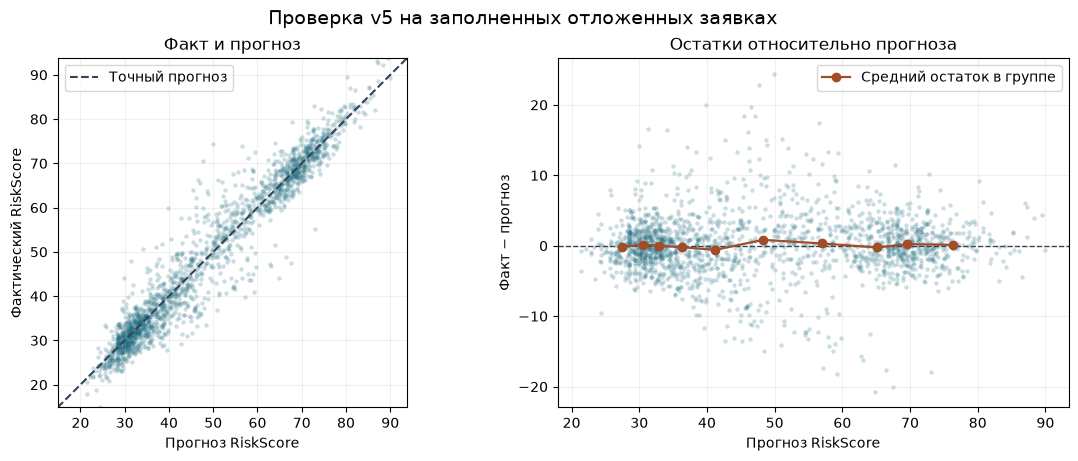

In [25]:
actual = y_hold[complete_hold]
predicted = p5[complete_hold]
residual = actual - predicted
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
bounds = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].scatter(predicted, actual, s=10, alpha=.23, linewidths=0, color="#216c80")
axes[0].plot(bounds, bounds, linestyle="--", color="#374254", label="Точный прогноз")
axes[0].set(title="Факт и прогноз", xlabel="Прогноз RiskScore", ylabel="Фактический RiskScore",
            xlim=bounds, ylim=bounds, aspect="equal")
axes[0].legend()

axes[1].scatter(predicted, residual, s=10, alpha=.23, linewidths=0, color="#216c80")
axes[1].axhline(0, linestyle="--", color="#374254", linewidth=1)
residuals = pd.DataFrame({"прогноз": predicted, "остаток": residual})
groups = pd.qcut(residuals["прогноз"], 10, duplicates="drop")
means = residuals.groupby(groups, observed=True).mean()
axes[1].plot(means["прогноз"], means["остаток"], color="#a04d28", marker="o",
             linewidth=1.6, label="Средний остаток в группе")
axes[1].set(title="Остатки относительно прогноза", xlabel="Прогноз RiskScore",
            ylabel="Факт − прогноз")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(alpha=.18)
fig.suptitle("Проверка v5 на заполненных отложенных заявках", fontsize=14)
plt.show()

In [26]:
all_features = Features(basis="conservative_v5").fit(X)
final_model = RegularizedRegression(lp=.002).fit(all_features.transform(X), y)
test_prediction = final_model.predict(all_features.transform(test[features]))
assert len(test_prediction) == len(test) and np.isfinite(test_prediction).all()

# ex.csv задаёт формат и порядок строк. Его примерные значения RiskScore не используются.
submission = pd.read_csv(data_dir / "ex.csv")
assert submission.columns.tolist() == ["ID", TARGET]
assert submission.ID.is_unique and test.ID.is_unique and len(submission) == len(test)
assert set(submission.ID) == set(test.ID)
submission[TARGET] = submission.ID.map(pd.Series(test_prediction, index=test.ID))
destination = LAB / "submission.csv"
submission.to_csv(destination, index=False)
check = pd.read_csv(destination)
np.testing.assert_array_equal(check.ID, submission.ID)
np.testing.assert_allclose(check[TARGET], submission[TARGET])
display(check.head())
print(f"Сохранено {len(check):,} прогнозов в {destination}.")

,ID,RiskScore
0,0,33.05435
1,1,53.92629
2,2,30.13120
3,3,34.68245
4,4,33.31727


Сохранено 5,000 прогнозов в lab1\submission.csv.


## Выводы для защиты

На 1 868 заполненных отложенных заявках MSE уменьшился с 19,574 у первой версии до 19,123 у третьей, 18,921 у четвёртой и **18,752** у пятой. У v5 ошибка стала меньше на второй половине этой выборки и немного выросла на первой. На всех 1 958 отложенных заявках, включая строки с пропусками, MSE v5 составил **20,303**. В тестовом файле Kaggle все 5 000 заявок заполнены.

При пяти фолдах и seed 117 на 9 332 заполненных заявках MSE составил 18,146 для v4 и 18,085 для v5. Разбиения использовались при доработке, поэтому оценки могут быть оптимистичны. Для публикации ноутбука в задании указан MSE ниже 25,00. Официальный результат для скрытой выборки вычисляет Kaggle.

## К защите

- **Почему важна отложенная выборка?** Ошибка на обучающих объектах оптимистична. Пять фолдов помогают выбрать вариант модели, а отложенная часть даёт отдельную оценку после выбора.
- **Чем различаются методы обучения?** МНК решает задачу линейной алгебры. GD использует всю выборку на каждом шаге, SGD — одну строку. Все три оценивают коэффициенты одной линейной модели.
- **Зачем масштабировать признаки?** Для спуска это выравнивает размеры шагов по разным координатам. Для регуляризации это делает штраф сопоставимым для признаков в разных единицах.
- **Почему проверяем несколько метрик?** MAE удобно читать в единицах цели, MSE сильнее наказывает за крупные промахи, $R^2$ даёт сравнение с прогнозом средним, а MAPE выражает относительную ошибку и нестабильна около нуля.
- **Как различаются штрафы?** L1 может обнулять отдельные коэффициенты, L2 плавно уменьшает веса, Elastic Net сочетает оба эффекта. В Lp степень задаёт форму штрафа.
- **Что считать выполнением порога?** Таблица на отложенной части показывает локальную оценку. Балл для допуска берётся из результата посылки на Kaggle.